# 응용 04 · VLM 응답의 근거 점검

`04_mock_compare.py`의 A04 구현을 설명하고, 제공된 모의 응답 15개의 근거를 시각화합니다. 실제 VLM 호출이나 성능 측정은 수행하지 않습니다.

저장소 내부에서 Python 커널로 순서대로 실행하세요. pandas, Matplotlib, IPython이 필요합니다. 데이터는 `data/lesson.json`에서 읽고 결과는 메모리에서 확인합니다. CSV 저장은 마지막 셀의 주석을 해제하면 됩니다.

## 1. 무엇을 검사할까?

각 응답의 `evidence`가 **그 응답에 해당하는 문서의 OCR 원문**에 포함되는지 검사합니다. 다른 문서의 텍스트를 합쳐 검색하면 안 됩니다.

```python
evidence_found = answer['evidence'] in doc['ocr']['text']
```

`in`은 대소문자·공백·줄바꿈까지 구분하는 부분 문자열 검사입니다. 정규식으로 새 값을 추출하는 실습이 아닙니다. `re`가 원본에 import되어 있어도 A04에서는 필요하지 않습니다.

**처리 흐름:** 문서 선택 → 제공 응답 선택 → 동일 문서 OCR에서 근거 검색 → 발견 여부 기록 → 미발견이면 검토 대상으로 표시


In [1]:
from pathlib import Path
import json
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display

start = Path.cwd().resolve()
project = next((p for p in [start, *start.parents]
                if (p / '20261109/02_intermediate/04_mock_compare.py').is_file()), None)
if project is None:
    raise FileNotFoundError('저장소 내부에서 실행하세요.')
base = project / '20261109/02_intermediate'
lesson = json.loads((base / 'data/lesson.json').read_text(encoding='utf-8'))
print('문서 수:', len(lesson['documents']))


문서 수: 5


## 2. 현재 A04 코드 실행

원본 파일의 TODO 블록을 읽어 사용하므로 원본 구현을 변경하면 재실행 시 반영됩니다. `response`의 필드·답·근거를 유지하고, `review`에는 근거 미발견 여부를 저장합니다. 여기서 `review=False`는 이 검사에서 검토 대상으로 표시되지 않았다는 의미이며 답이 정답이라는 보장은 아닙니다.


In [2]:
source = (base / '04_mock_compare.py').read_text(encoding='utf-8')
block = textwrap.dedent(source.split('# TODO A04', 1)[1].split('# TODO 끝 A04', 1)[0])
print('현재 A04 구현:', block.strip())
rows = []
for name, doc in lesson['documents'].items():
    for answer in doc['mock_vlm']['responses']:
        scope = {'answer': answer, 'doc': doc}
        exec(compile(block, str(base / '04_mock_compare.py'), 'exec'), scope)
        found = scope['evidence_found']
        rows.append({'document_id': name, 'backend': 'mock', **answer,
                     'evidence_found': found, 'review': not found})
table = pd.DataFrame(rows)
display(table)
print('mock 필드:', len(table), '근거 문자열 발견:', int(table['evidence_found'].sum()))


현재 A04 구현: evidence_found = answer['evidence'] in doc['ocr']['text']


,document_id,backend,field,answer,evidence,evidence_found,review
0,doc01,mock,issued_at,2026-11-01,DATE: 2026-11-01,True,False
1,doc01,mock,supplier,BLUE CAFE,SUPPLIER: BLUE CAFE,True,False
2,doc01,mock,total_amount,27000,TOTAL: 27000,True,False
3,doc02,mock,issued_at,2026-11-02,DATE: 2026-11-02,True,False
4,doc02,mock,supplier,PINE BOOKS,SUPPLIER: PINE BOOKS,True,False
5,doc02,mock,total_amount,18000,TOTAL: 18000,True,False
6,doc03,mock,issued_at,2026-11-03,DATE: 2026-11-03,True,False
7,doc03,mock,supplier,ALPHA STUDIO,SUPPLIER: ALPHA STUDIO,True,False
8,doc03,mock,total_amount,33000,TOTAL: 33000,True,False
9,doc04,mock,issued_at,2026-11-04,DATE: 2026-11-04,True,False


mock 필드: 15 근거 문자열 발견: 13


## 3. 문서 × 필드 근거 발견 현황

초록색은 근거 문자열 발견, 주황색은 미발견입니다. 모든 칸은 동일 문서의 OCR 원문만 검사한 결과입니다. 차트는 한글 폰트 설치 없이 볼 수 있도록 영문으로 표시합니다.


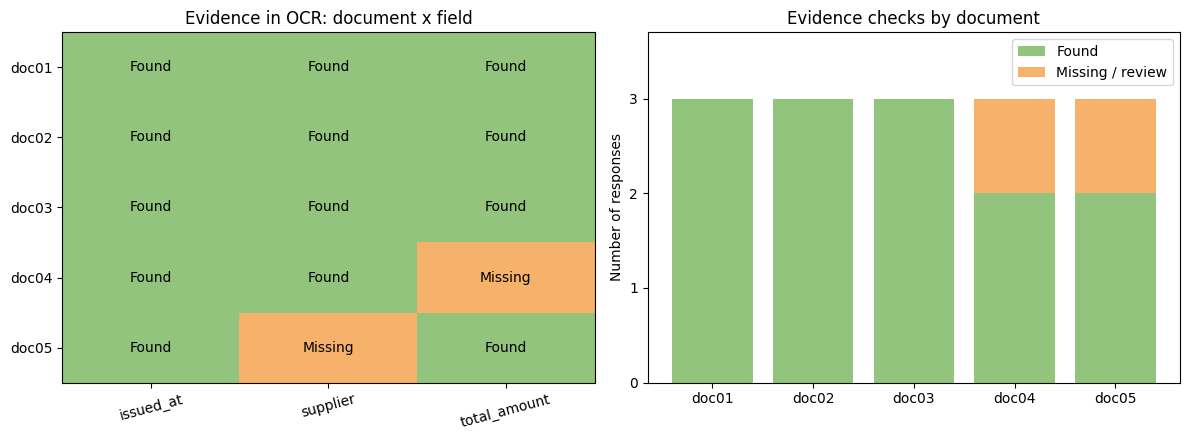

In [3]:
fields = ['issued_at', 'supplier', 'total_amount']
matrix = table.pivot(index='document_id', columns='field', values='evidence_found')[fields]
summary = table.groupby('document_id')['evidence_found'].agg(['sum', 'count'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(matrix.astype(int), cmap=ListedColormap(['#f6b26b', '#93c47d']), vmin=0, vmax=1, aspect='auto')
axes[0].set_xticks(range(len(fields)), fields, rotation=15)
axes[0].set_yticks(range(len(matrix)), matrix.index)
for row in range(len(matrix)):
    for col in range(len(fields)):
        axes[0].text(col, row, 'Found' if matrix.iloc[row, col] else 'Missing', ha='center', va='center')
axes[0].set_title('Evidence in OCR: document x field')
axes[1].bar(summary.index, summary['sum'], label='Found', color='#93c47d')
axes[1].bar(summary.index, summary['count'] - summary['sum'], bottom=summary['sum'], label='Missing / review', color='#f6b26b')
axes[1].set_ylim(0, 3.7)
axes[1].set_yticks([0, 1, 2, 3])
axes[1].set_ylabel('Number of responses')
axes[1].set_title('Evidence checks by document')
axes[1].legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## 4. 근거가 없는 응답을 원문과 비교

미발견은 오답 판정과 다릅니다. OCR 오인식이나 표기 차이 때문에 근거가 검색되지 않을 수도 있습니다. 아래에는 응답의 근거 문자열과 해당 문서의 OCR 원문을 함께 표시합니다.


In [4]:
review_rows = table.loc[table['review']]
display(review_rows[['document_id', 'field', 'answer', 'evidence']])
for row in review_rows.itertuples():
    print(f'[{row.document_id} / {row.field}]')
    print('제공 답:', row.answer)
    print('제공 근거:', row.evidence)
    print('해당 문서 OCR 원문:')
    print(lesson['documents'][row.document_id]['ocr']['text'])
    print()


,document_id,field,answer,evidence
11,doc04,total_amount,99999,TOTAL: 99999
13,doc05,supplier,LIME LAB,not visible in this crop


[doc04 / total_amount]
제공 답: 99999
제공 근거: TOTAL: 99999
해당 문서 OCR 원문:
INVOICE DOC04
DATE: 2026-11-04
SUPPLIER: NOVA MARKET
ITEM QTY PRICE AMOUNT
MILK 2 2500 5000
BREAD 1 3500 3500
FRUIT 2 2000 4000
TOTAL: 12500
CURRENCY: KRW

[doc05 / supplier]
제공 답: LIME LAB
제공 근거: not visible in this crop
해당 문서 OCR 원문:
INVOICE DOCO5
DATE: 2026-11-05
SUPPLIER: LIME LAB
ITEM QTY PRICE AMOUNT
KIT 2 5000 10000
TUBE 4 2000 8000
BOX 2 3000 6000
TOTAL: 24000
CURRENCY: KRW



## 5. 답의 정확성과 근거의 존재를 분리해서 보기

아래 정답 비교는 A04의 근거 검사에 대한 **보충 설명**입니다. `truth`와 제공 답을 직접 비교하며 형식 정규화는 하지 않습니다. A04의 `review` 규칙은 그대로 유지합니다.

근거가 검색돼도 질문에 맞는 라벨과 값인지까지 검증한 것은 아닙니다. 반대로 답이 정답과 같아도 근거가 없으면 A04에서는 검토 대상으로 표시합니다.


,document_id,field,answer,truth,answer_correct,evidence_found,review
0,doc01,issued_at,2026-11-01,2026-11-01,True,True,False
1,doc01,supplier,BLUE CAFE,BLUE CAFE,True,True,False
2,doc01,total_amount,27000,27000,True,True,False
3,doc02,issued_at,2026-11-02,2026-11-02,True,True,False
4,doc02,supplier,PINE BOOKS,PINE BOOKS,True,True,False
5,doc02,total_amount,18000,18000,True,True,False
6,doc03,issued_at,2026-11-03,2026-11-03,True,True,False
7,doc03,supplier,ALPHA STUDIO,ALPHA STUDIO,True,True,False
8,doc03,total_amount,33000,33000,True,True,False
9,doc04,issued_at,2026-11-04,2026-11-04,True,True,False


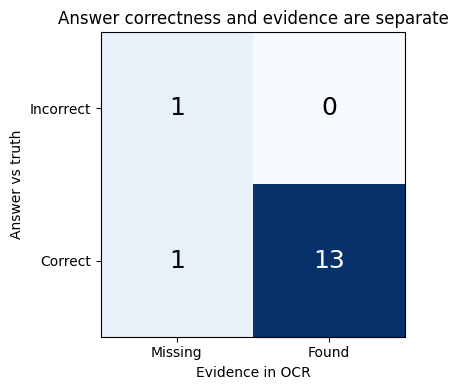

In [5]:
comparison = table.copy()
comparison['truth'] = [lesson['documents'][r.document_id]['truth'][r.field]
                       for r in comparison.itertuples()]
comparison['answer_correct'] = [r.answer == r.truth for r in comparison.itertuples()]
display(comparison[['document_id', 'field', 'answer', 'truth', 'answer_correct', 'evidence_found', 'review']])
counts = pd.crosstab(comparison['answer_correct'], comparison['evidence_found']).reindex(
    index=[False, True], columns=[False, True], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(counts, cmap='Blues', vmin=0, vmax=max(1, counts.to_numpy().max()))
ax.set_xticks([0, 1], ['Missing', 'Found'])
ax.set_yticks([0, 1], ['Incorrect', 'Correct'])
ax.set_xlabel('Evidence in OCR')
ax.set_ylabel('Answer vs truth')
ax.set_title('Answer correctness and evidence are separate')
for row in range(2):
    for col in range(2):
        value = int(counts.iloc[row, col])
        ax.text(col, row, str(value), ha='center', va='center', fontsize=18,
                color='white' if value > counts.to_numpy().max() / 2 else 'black')
fig.tight_layout()
display(fig)
plt.close(fig)


## 6. 현재 데이터의 해석과 한계

- 5개 문서 × 3개 필드 = 15개 응답 중 근거 문자열은 13개에서 발견되고, 2개는 검토 대상으로 표시됩니다.
- `doc04 / total_amount`: 제공 답 `99999`의 근거 `TOTAL: 99999`가 OCR 원문에 없습니다. 제공 답도 정답과 다릅니다.
- `doc05 / supplier`: 제공 답 `LIME LAB`은 정답과 같지만, 근거 `not visible in this crop`은 OCR 원문에 없습니다. 따라서 `review=True`로 표시합니다.
- 빈 문자열은 어떤 문자열에도 포함되므로, 일반 데이터에서 빈 근거를 거부하려면 `bool(evidence.strip())` 같은 추가 조건이 필요합니다. 현재 실습 데이터의 근거는 모두 비어 있지 않습니다.
- OCR 텍스트 포함 검사는 이미지의 실제 위치, 의미적 뒷받침, 라벨과 답의 일치, 환각 여부를 완전히 검증하지 않습니다.
- 이 수치는 강사가 작성한 모의 응답의 점검 결과입니다. 실제 VLM 정확도나 GPU 처리시간으로 보고하면 안 됩니다.

**설명 질문 답:** 정답값이 맞더라도 근거가 없으면 `evidence_found=False`, `review=True`로 표시하고 사람이 확인합니다.

## 7. 선택: CSV 저장

원본 스크립트와 동일한 열과 UTF-8 BOM 인코딩을 사용합니다. 아래 주석을 해제하면 `outputs/p04_mock_review.csv`를 생성하거나 덮어씁니다.


In [6]:
# out = base / 'outputs'
# out.mkdir(exist_ok=True)
# table.to_csv(out / 'p04_mock_review.csv', index=False, encoding='utf-8-sig')
